<a href="https://colab.research.google.com/github/david-ruizn/taller-pandas-olimpiadas-grupoX/blob/Archivo-final/Proyecto_pandas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto PANDAS Programación 2.
## Integrantes.
- Alejandro Pachón Cortés
- David Alejandro Ruiz Nuñez
-  Ometh David Mejía Ospino

  
    
## 1)

In [ ]:
import pandas as pd
athlete_events = pd.read_csv("Datos/athlete_events.csv")
noc_regions = pd.read_csv("Datos/noc_regions.csv")

# 2)
## athlete_events
- ID: ID única de cada atleta.  
- Name: Nombre del atleta.  
- Sex: Sexo del atleta.  
- Age: Edad del atleta en la participación correspondiente al registro.  
- Height: Altura del atleta en la participación correspondiente al registro.  
- Weight: Peso del atleta en la participación correspondiente al registro.
- Team: Equipo con el cual el atleta participó en la edición correspondiente al registro.  
- NOC: Código del Comité Olímpico National (National Olympic Comitee) al cual el atleta estaba inscrito y representó durante la edición correspondiente al registro.  
- Games: Edición de los juegos olímpicos de la que el atleta fue partícipe en el registro particular.  
- Year: Año de la edición de la cual el atleta fue participe en el registro particular.  
- Season: Modalidad de los juegos olímpicos correspondiente a la participación correspondiente al registro (Verano/Invierno).  
- City: Ciudad en la que se desarrolló el evento del cual fue partícipe el atleta durante la edición correspondiente al registro.  
- Sport: Deporte practicado por el atleta durante la edición correspondiente al registro.  
- Event: Evento en el cual el atleta participó durante la edición correspondiente al registro.  
- Medal: Medalla obtenida por el atleta tras su participación en la edición correspondiente al registro.  

## noc_regions
- NOC: Código del Comité Olímpico National (National Olympic Comitee).  
- region: Comité Olímpico Nacional de la región geográfica actual (usualmente país) a la cual corresponde el código NOC.
- notes: Notas sobre la entrada (Por ejemplo, si el país correspondiente al NOC ya no existe (Mire entrada 227, Yugoslavia), se hace la aclaración de que el país extinto era al que se refería el código NOC).

## 3)

In [ ]:
print(athlete_events.describe())

                  ID            Age         Height         Weight  \
count  271116.000000  261642.000000  210945.000000  208241.000000   
mean    68248.954396      25.556898     175.338970      70.702393   
std     39022.286345       6.393561      10.518462      14.348020   
min         1.000000      10.000000     127.000000      25.000000   
25%     34643.000000      21.000000     168.000000      60.000000   
50%     68205.000000      24.000000     175.000000      70.000000   
75%    102097.250000      28.000000     183.000000      79.000000   
max    135571.000000      97.000000     226.000000     214.000000   

                Year  
count  271116.000000  
mean     1978.378480  
std        29.877632  
min      1896.000000  
25%      1960.000000  
50%      1988.000000  
75%      2002.000000  
max      2016.000000  


In [ ]:
print(noc_regions.describe())

        NOC   region                 notes
count   230      227                    21
unique  230      206                    21
top     AFG  Germany  Netherlands Antilles
freq      1        4                     1


# 3.5) Limpieza de datos

In [ ]:
import math
import matplotlib.pyplot as plt
import numpy as np
# Número de bins a utilizar en el histograma.
n = len(athlete_events.ID)
k = 1 + math.log(n, 2)
print (k)

19.04855073124767


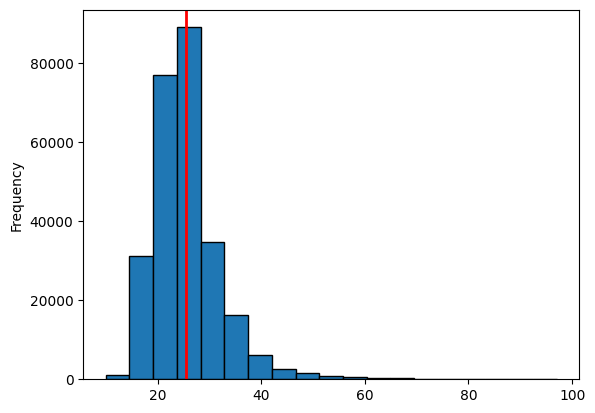

In [ ]:
# Age
athlete_events['Age'].plot(kind="hist", bins=19, edgecolor="black")
plt.axvline(np.mean(athlete_events.Age), color="red", linewidth=2)

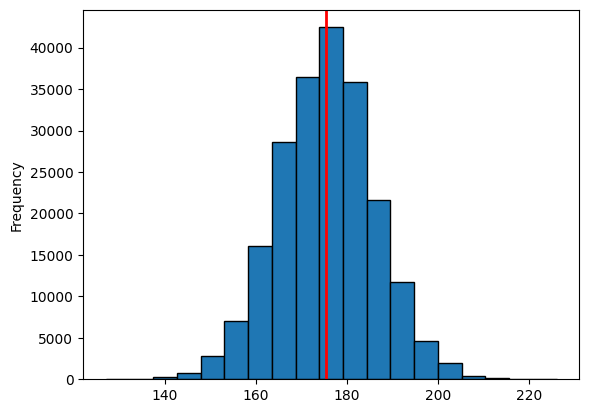

In [ ]:
# Height
athlete_events['Height'].plot(kind="hist", bins=19, edgecolor="black")
plt.axvline(np.mean(athlete_events.Height), color="red", linewidth=2)

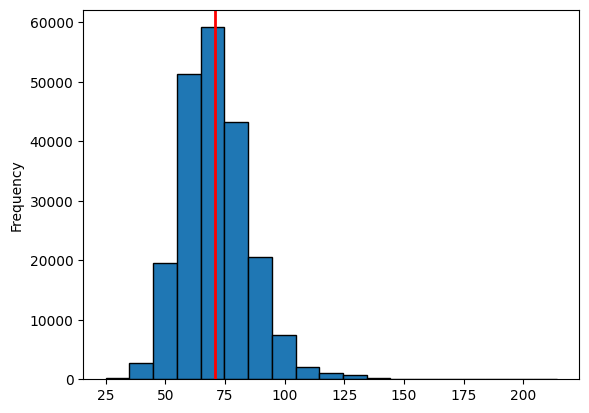

In [ ]:
# Weight
athlete_events['Weight'].plot(kind="hist", bins=19, edgecolor="black")
plt.axvline(np.mean(athlete_events.Weight), color="red", linewidth=2)

Como en las distribuciones se ve que la mayoría de datos se concentran cerca de la media, y, además, no hay colas pesadas que puedan afectar esta última, se decide reemplazar los NAs por la media.

In [ ]:
# Reemplazo de los NAs por la media
athlete_events["Age"] = athlete_events["Age"].fillna(np.mean(athlete_events.Age))
athlete_events["Height"] = athlete_events["Height"].fillna(np.mean(athlete_events.Height))
athlete_events["Weight"] = athlete_events["Weight"].fillna(np.mean(athlete_events.Weight))

In [ ]:
# Verificación con .describe()
print(athlete_events.describe())

                  ID            Age        Height         Weight  \
count  271116.000000  271116.000000  271116.00000  271116.000000   
mean    68248.954396      25.556898     175.33897      70.702393   
std     39022.286345       6.280857       9.27810      12.574690   
min         1.000000      10.000000     127.00000      25.000000   
25%     34643.000000      22.000000     170.00000      63.000000   
50%     68205.000000      25.000000     175.33897      70.702393   
75%    102097.250000      28.000000     180.00000      75.000000   
max    135571.000000      97.000000     226.00000     214.000000   

                Year  
count  271116.000000  
mean     1978.378480  
std        29.877632  
min      1896.000000  
25%      1960.000000  
50%      1988.000000  
75%      2002.000000  
max      2016.000000  


#4)
###Nueva variable IMC

In [ ]:
athlete_events['IMC'] = athlete_events['Weight'] / (athlete_events['Height']/100) ** 2

#5)
Fusionar lo datasets

In [ ]:
fusionado = athlete_events.merge(noc_regions, how='left', on='NOC')

Se utilizó 'left' para que se prioricen los datos de althete_events unidos con los de noc_regions y mezclandolos a partir de la variable NOC por eso se usa on= 'NOC'


In [ ]:
display(athlete_events)
display(fusionado)

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal,IMC
0,1,A Dijiang,M,24.0,180.00000,80.000000,China,CHN,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,NaN,24.691358
1,2,A Lamusi,M,23.0,170.00000,60.000000,China,CHN,2012 Summer,2012,Summer,London,Judo,Judo Men's Extra-Lightweight,NaN,20.761246
2,3,Gunnar Nielsen Aaby,M,24.0,175.33897,70.702393,Denmark,DEN,1920 Summer,1920,Summer,Antwerpen,Football,Football Men's Football,NaN,22.997319
3,4,Edgar Lindenau Aabye,M,34.0,175.33897,70.702393,Denmark/Sweden,DEN,1900 Summer,1900,Summer,Paris,Tug-Of-War,Tug-Of-War Men's Tug-Of-War,Gold,22.997319
4,5,Christine Jacoba Aaftink,F,21.0,185.00000,82.000000,Netherlands,NED,1988 Winter,1988,Winter,Calgary,Speed Skating,Speed Skating Women's 500 metres,NaN,23.959094
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
271111,135569,Andrzej ya,M,29.0,179.00000,89.000000,Poland-1,POL,1976 Winter,1976,Winter,Innsbruck,Luge,Luge Mixed (Men)'s Doubles,NaN,27.776911
271112,135570,Piotr ya,M,27.0,176.00000,59.000000,Poland,POL,2014 Winter,2014,Winter,Sochi,Ski Jumping,"Ski Jumping Men's Large Hill, Individual",NaN,19.047004
271113,135570,Piotr ya,M,27.0,176.00000,59.000000,Poland,POL,2014 Winter,2014,Winter,Sochi,Ski Jumping,"Ski Jumping Men's Large Hill, Team",NaN,19.047004
271114,135571,Tomasz Ireneusz ya,M,30.0,185.00000,96.000000,Poland,POL,1998 Winter,1998,Winter,Nagano,Bobsleigh,Bobsleigh Men's Four,NaN,28.049671


,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal,IMC,region,notes
0,1,A Dijiang,M,24.0,180.00000,80.000000,China,CHN,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,NaN,24.691358,China,NaN
1,2,A Lamusi,M,23.0,170.00000,60.000000,China,CHN,2012 Summer,2012,Summer,London,Judo,Judo Men's Extra-Lightweight,NaN,20.761246,China,NaN
2,3,Gunnar Nielsen Aaby,M,24.0,175.33897,70.702393,Denmark,DEN,1920 Summer,1920,Summer,Antwerpen,Football,Football Men's Football,NaN,22.997319,Denmark,NaN
3,4,Edgar Lindenau Aabye,M,34.0,175.33897,70.702393,Denmark/Sweden,DEN,1900 Summer,1900,Summer,Paris,Tug-Of-War,Tug-Of-War Men's Tug-Of-War,Gold,22.997319,Denmark,NaN
4,5,Christine Jacoba Aaftink,F,21.0,185.00000,82.000000,Netherlands,NED,1988 Winter,1988,Winter,Calgary,Speed Skating,Speed Skating Women's 500 metres,NaN,23.959094,Netherlands,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
271111,135569,Andrzej ya,M,29.0,179.00000,89.000000,Poland-1,POL,1976 Winter,1976,Winter,Innsbruck,Luge,Luge Mixed (Men)'s Doubles,NaN,27.776911,Poland,NaN
271112,135570,Piotr ya,M,27.0,176.00000,59.000000,Poland,POL,2014 Winter,2014,Winter,Sochi,Ski Jumping,"Ski Jumping Men's Large Hill, Individual",NaN,19.047004,Poland,NaN
271113,135570,Piotr ya,M,27.0,176.00000,59.000000,Poland,POL,2014 Winter,2014,Winter,Sochi,Ski Jumping,"Ski Jumping Men's Large Hill, Team",NaN,19.047004,Poland,NaN
271114,135571,Tomasz Ireneusz ya,M,30.0,185.00000,96.000000,Poland,POL,1998 Winter,1998,Winter,Nagano,Bobsleigh,Bobsleigh Men's Four,NaN,28.049671,Poland,NaN


#6)
###Nueva variable medalla

In [ ]:
# Recalculamos la columna binaria 'medalla' con los nuevos datos correctivos
fusionado['medalla'] = fusionado['Medal'].isin(['Gold', 'Silver', 'Bronze']).astype(int)


# 7)

1896
2016


<Axes: xlabel='Year'>

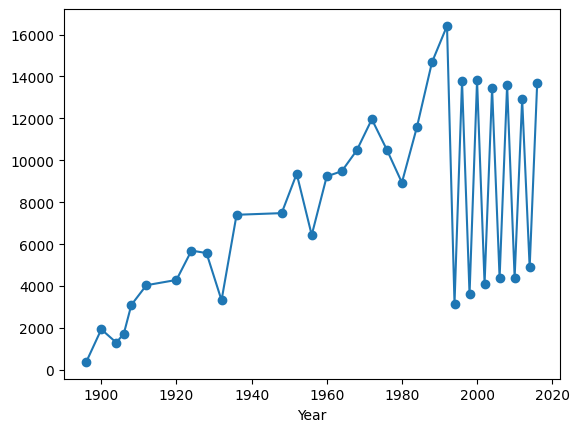

In [ ]:
print(min(fusionado["Year"]))
print(max(fusionado["Year"]))

# Epoca
epoca = fusionado.groupby("Year").size()
epoca.plot(marker="o")

,0
Season,
Summer,222552
Winter,48564


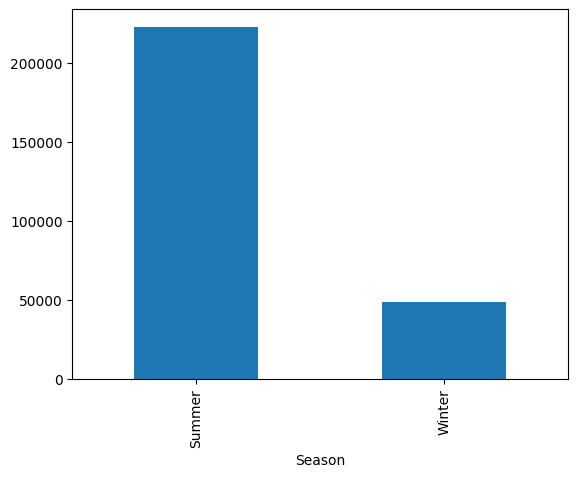

In [ ]:
# Temporada
tempo = fusionado.groupby("Season").size()
tempo.plot.bar()
display(tempo)

,0
Sex,
F,74522
M,196594


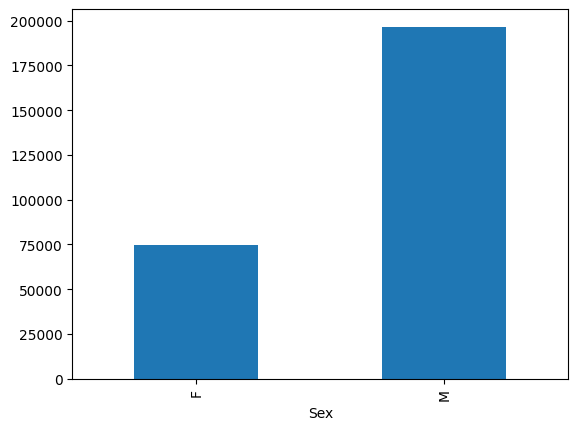

In [ ]:
# Sexo
sexo = fusionado.groupby("Sex").size()
sexo.plot.bar()
display(sexo)

#8)


In [ ]:
nulos_globales = fusionado.isnull().sum()
columnas_con_nulos = nulos_globales[nulos_globales > 0].index
display(fusionado[columnas_con_nulos].isnull().sum())

,0
Medal,231333
region,370
notes,266077


In [ ]:
fusionado['Era'] = fusionado['Year'].apply(lambda y: 'Antes de 1960' if y < 1960 else 'Después de 1960')

columnas_con_nulos = fusionado.columns[fusionado.isnull().any()]

comparacion_eras = fusionado.groupby('Era')[columnas_con_nulos].apply(lambda x: (x.isnull().mean() * 100))
display(comparacion_eras)

fusionado.drop(columns=['Era'], inplace=True)

,Medal,region,notes
Era,,,
Antes de 1960,81.653343,0.099929,98.069112
Después de 1960,86.416163,0.147318,98.162834


#9)

In [ ]:
#a
promedio = fusionado["Age"].mean()
print(promedio)

25.556898357297374


In [ ]:
#b
fusionado["medalla"].value_counts()

,count
medalla,
0,231333
1,39783


In [ ]:
#c
estaturaG =  fusionado.loc[fusionado['Medal'] == 'Gold','Height'].mean()
print(estaturaG)

177.35621460156216


In [ ]:
#d
ediciones = fusionado["Games"].nunique()
nocs = fusionado["NOC"].nunique()
print(ediciones,nocs)

51 230


In [ ]:
#e
joven = fusionado['Age'].min()
viejo = fusionado['Age'].max()
print(joven, viejo)

10.0 97.0


In [ ]:
#f
fusionado["Season"].value_counts()

,count
Season,
Summer,222552
Winter,48564


In [ ]:
#g
unicos = (fusionado.groupby("ID")["Games"].nunique() == 1).sum()
varias = (fusionado.groupby("ID")["Games"].nunique() > 1).sum()

print( unicos)
print( varias)

98450
37121


# 10)

In [ ]:
# a)
p10a = fusionado.groupby(["Sex", "medalla"]).size()
display(p10a)
print("-----")
print(f"Medallas Mujeres: {p10a["F"][1]}")
print(f"Medallas Hombres: {p10a["M"][1]}")
print(f"Proporción medallas Mujeres: {p10a["F"][1]/p10a["F"].sum()}")
print(f"Proporción medallas Hombres: {p10a["M"][1]/p10a["M"].sum()}")


# b)
p10b = fusionado.groupby([fusionado.Age<18, "medalla"]).size()
display(p10b)
print("-----")
print(f"Medallas Menores de edad: {p10b[True][1]}")
print(f"Medallas Mayores de edad: {p10b[False][1]}")
print(f"Proporción medallas Menores de edad: {p10b[True][1]/p10b[True].sum()}")
print(f"Proporción medallas Mayores de edad: {p10b[False][1]/p10b[False].sum()}")


# c)
p10c = fusionado.groupby([(fusionado.Age<18)|(fusionado.Age>=35), "medalla"]).size()
display(p10c)
print("-----")
print(f"Medallas Dentro del grupo etario (edad<18, edad>=35): {p10c[True][1]}")
print(f"Medallas En otro grupo etario (18<=edad<35): {p10c[False][1]}")
print(f"Proporción medallas Dentro del grupo etario (edad<18, edad>=35): {p10c[True][1]/p10c[True].sum()}")
print(f"Proporción medallas En otro grupo etario (18<=edad<35): {p10c[False][1]/p10c[False].sum()}")

# d)
p10d = fusionado.groupby([fusionado.region == "USA", "medalla"]).size()
display(p10d)
print("-----")
print(f"Medallas Representantes USA: {p10d[True][1]}")
print(f"Medallas Representantes otros países: {p10d[False][1]}")
print(f"Proporción medallas Representantes USA: {p10d[True][1]/p10d[True].sum()}")
print(f"Proporción medallas Representantes otros países: {p10d[False][1]/p10d[False].sum()}")

# e)
p10e = fusionado.groupby([fusionado.Season == "Summer", "medalla"]).size()
display(p10e)
print("-----")
print(f"Medallas Verano: {p10e[True][1]}")
print(f"Medallas Invierno: {p10e[False][1]}")
print(f"Proporción medallas Verano: {p10e[True][1]/p10e[True].sum()}")
print(f"Proporción medallas Invierno: {p10e[False][1]/p10e[False].sum()}")

Sex  medalla
F    0           63269
     1           11253
M    0          168064
     1           28530
dtype: int64

-----
Medallas Mujeres: 11253
Medallas Hombres: 28530
Proporción medallas Mujeres: 0.15100238855639944
Proporción medallas Hombres: 0.14512141774418344


Age    medalla
False  0          220004
       1           38604
True   0           11329
       1            1179
dtype: int64

-----
Medallas Menores de edad: 1179
Medallas Mayores de edad: 38604
Proporción medallas Menores de edad: 0.09425967380876239
Proporción medallas Mayores de edad: 0.14927612448184124


Age    medalla
False  0          203293
       1           35798
True   0           28040
       1            3985
dtype: int64

-----
Medallas Dentro del grupo etario (edad<18, edad>=35): 3985
Medallas En otro grupo etario (18<=edad<35): 35798
Proporción medallas Dentro del grupo etario (edad<18, edad>=35): 0.12443403590944574
Proporción medallas En otro grupo etario (18<=edad<35): 0.14972541835535425


region  medalla
False   0          218117
        1           34146
True    0           13216
        1            5637
dtype: int64

-----
Medallas Representantes USA: 5637
Medallas Representantes otros países: 34146
Proporción medallas Representantes USA: 0.2989975070280592
Proporción medallas Representantes otros países: 0.13535873275113672


Season  medalla
False   0           42869
        1            5695
True    0          188464
        1           34088
dtype: int64

-----
Medallas Verano: 34088
Medallas Invierno: 5695
Proporción medallas Verano: 0.15316869765268343
Proporción medallas Invierno: 0.11726793509595586


#11)

141355
87990
41771


<Axes: xlabel='Sport'>

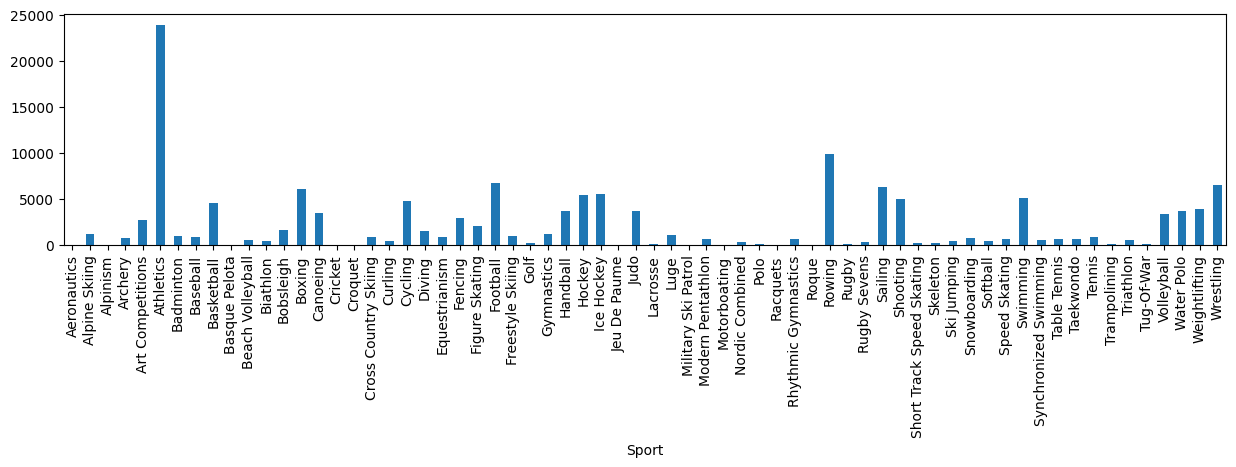

In [ ]:
fusionado["n_pruebas"] = (fusionado.groupby(["ID", "Games"])["Event"].transform("nunique"))
#display(fusionado.n_pruebas)

grupo1 = fusionado[fusionado.n_pruebas==1]
grupo2 = fusionado[(fusionado.n_pruebas==2)|(fusionado.n_pruebas==3)]
grupo3 = fusionado[fusionado.n_pruebas>=4]

print(len(grupo1.n_pruebas))
print(len(grupo2.n_pruebas))
print(len(grupo3.n_pruebas))

grupo1_sport = grupo1.groupby("Sport").size()
grupo2_sport = grupo2.groupby("Sport").size()
grupo3_sport = grupo3.groupby("Sport").size()

grupo1_sport.plot.bar(figsize=(15, 3))

<Axes: xlabel='Sport'>

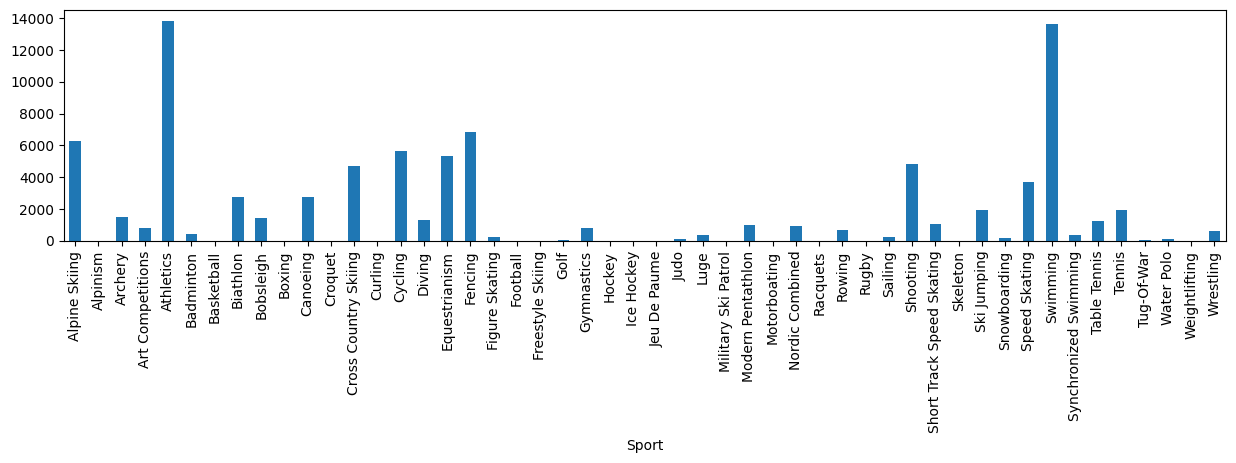

In [ ]:
grupo2_sport.plot.bar(figsize=(15, 3))

<Axes: xlabel='Sport'>

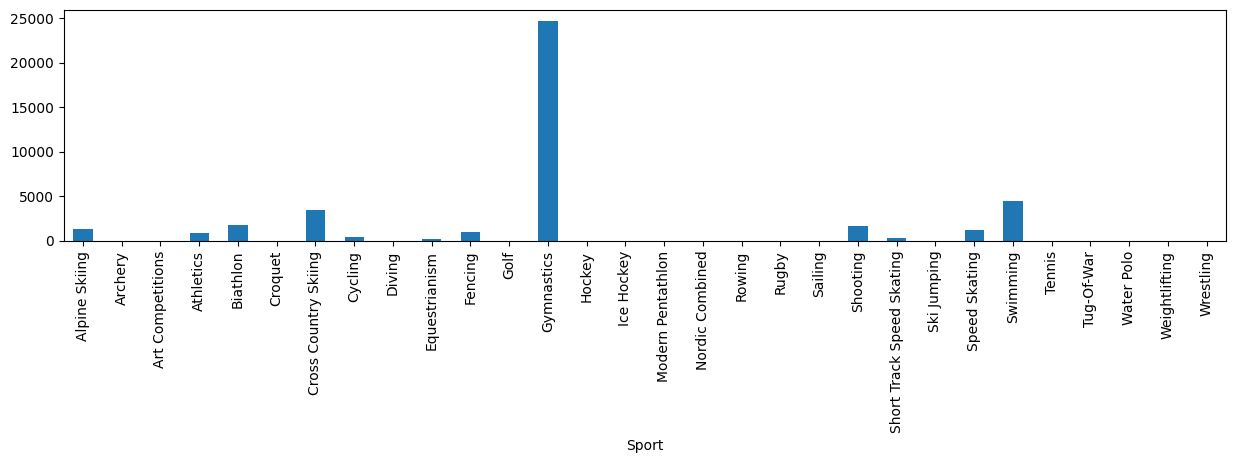

In [ ]:
grupo3_sport.plot.bar(figsize=(15, 3))

#12)


In [ ]:
fusionado['grupo etario'] = pd.cut(
    fusionado['Age'],
    bins=[-float('inf'), 18, 35, float('inf')],
    labels=['Menores', 'Jóvenes adultos', 'Mayores'],
    right=False
)

In [ ]:
fusionado['Estatura y peso'] = fusionado.apply(
    lambda x: 'Registrados'
    if pd.notna(x['Height']) and pd.notna(x['Weight'])
    else 'No registrados',
    axis=1
)

In [ ]:
resultado = fusionado.groupby(
    ['Sex', 'grupo etario', 'Estatura y peso', 'medalla']
).size().reset_index(name='Frecuencia')
#cambiar la agrupación a proporcion y luego a procentaje
resultado['Proporcion'] = (
    resultado['Frecuencia'] /
    resultado.groupby(
        ['Sex', 'grupo etario', 'Estatura y peso']
    )['Frecuencia'].transform('sum')
)

resultado['Porcentaje'] = resultado['Proporcion'] * 100


/tmp/ipykernel_1418/370831765.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  resultado = fusionado.groupby(
/tmp/ipykernel_1418/370831765.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  resultado.groupby(


Los atletas que no cuentan con una edad registrada se excluyen del análisis por grupos etarios, debido a que no es posible clasificarlos en ninguna de las tres categorías establecidas. Para esto se incluyo el observed=True al momento de crear resultado y adicionalmente para mayor seguridad se añadio dropna en grupo etario por si se le escapaba algun NA al observed=True

In [ ]:
tabla = resultado.pivot_table(
    index=['Sex', 'grupo etario', 'Estatura y peso'],
    columns='medalla',
    values='Porcentaje',
    fill_value=0
)
display(tabla.round(2))

/tmp/ipykernel_1418/616375149.py:1: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  tabla = resultado.pivot_table(


medalla                                  0      1
Sex grupo etario    Estatura y peso              
F   Menores         Registrados      90.50   9.50
    Jóvenes adultos Registrados      84.00  16.00
    Mayores         Registrados      86.15  13.85
M   Menores         Registrados      90.79   9.21
    Jóvenes adultos Registrados      85.39  14.61
    Mayores         Registrados      85.53  14.47

#13)

<Axes: xlabel='Year'>

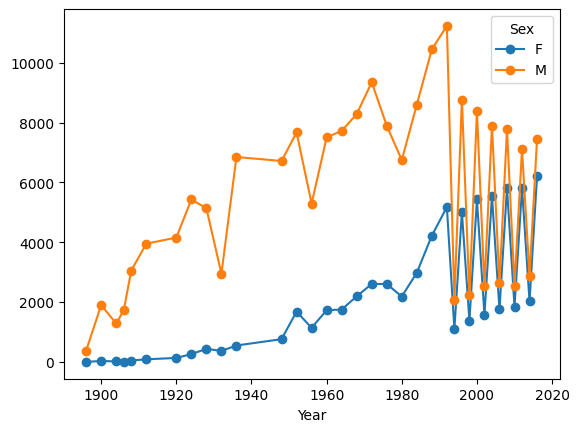

In [ ]:
# Gráfico 1: Genero y Año.
grafico1 = fusionado.groupby(["Year", "Sex"]).size().unstack(fill_value=0)
grafico1.plot(marker="o")

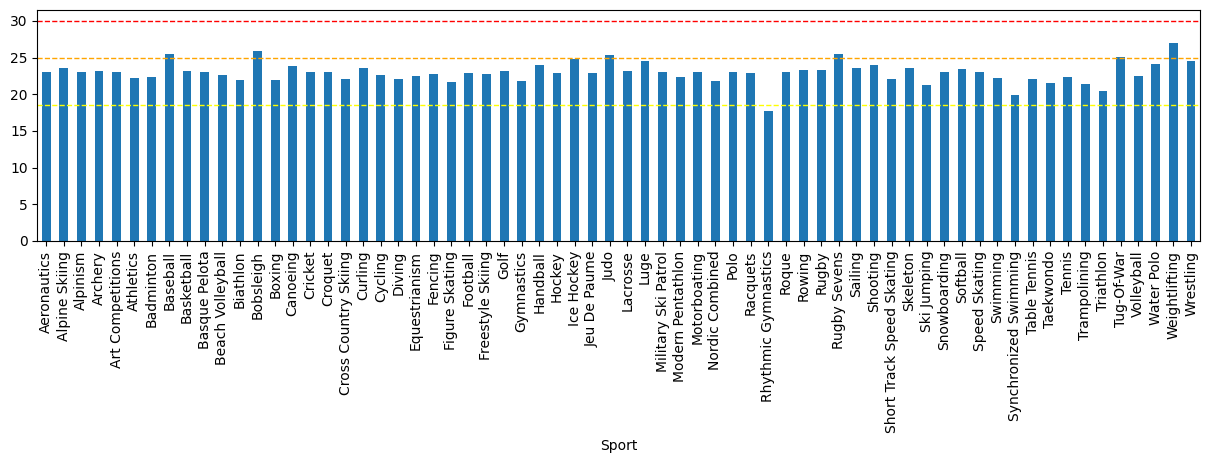

In [ ]:
# Gráfico 2: IMC y Deporte.
grafico2 = fusionado.groupby("Sport")
plot2 = grafico2["IMC"].mean().plot.bar(figsize=(15,3))
plot2.axhline(y=18.5, color='yellow', linestyle='--', linewidth=1)
plot2.axhline(y=25, color='orange', linestyle='--', linewidth=1)
plot2.axhline(y=30, color='red', linestyle='--', linewidth=1)

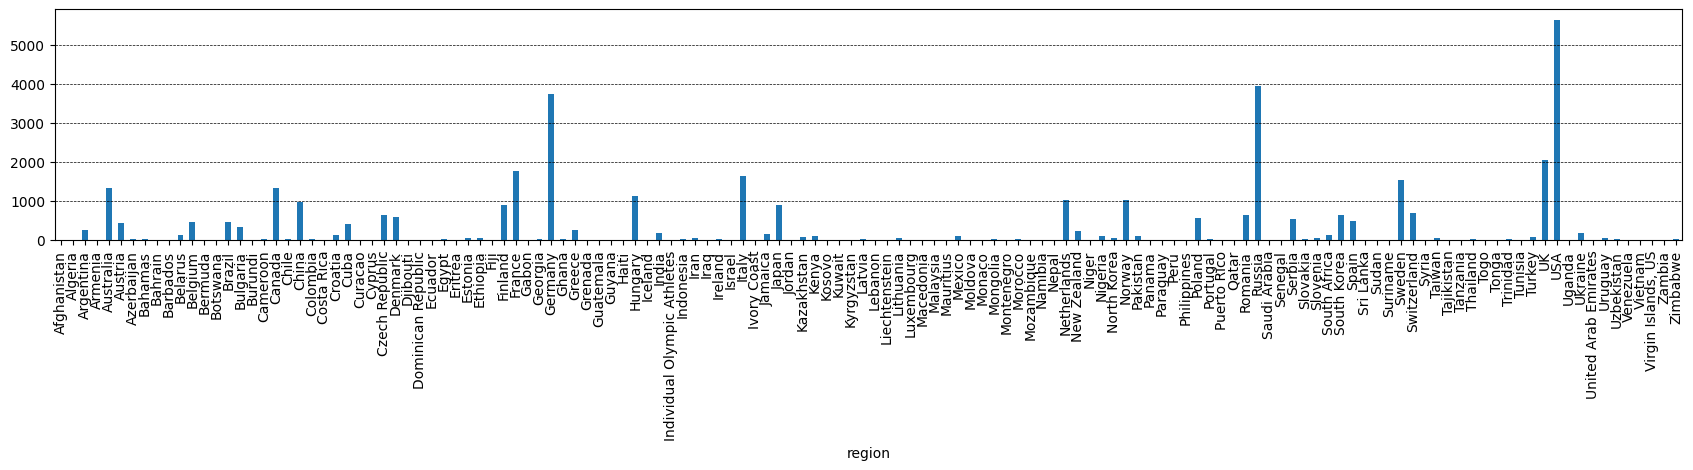

In [ ]:
# Gráfico #3: País y medallas.
grafico3 = fusionado.groupby("region").sum(numeric_only=True)
filtro3 = grafico3[grafico3.medalla>0]
plot3 = filtro3["medalla"].plot.bar(figsize=(21,3))
plot3.axhline(y=1000, color='black', linestyle='--', linewidth=0.5)
plot3.axhline(y=2000, color='black', linestyle='--', linewidth=0.5)
plot3.axhline(y=3000, color='black', linestyle='--', linewidth=0.5)
plot3.axhline(y=4000, color='black', linestyle='--', linewidth=0.5)
plot3.axhline(y=5000, color='black', linestyle='--', linewidth=0.5)

<Axes: xlabel='Year'>

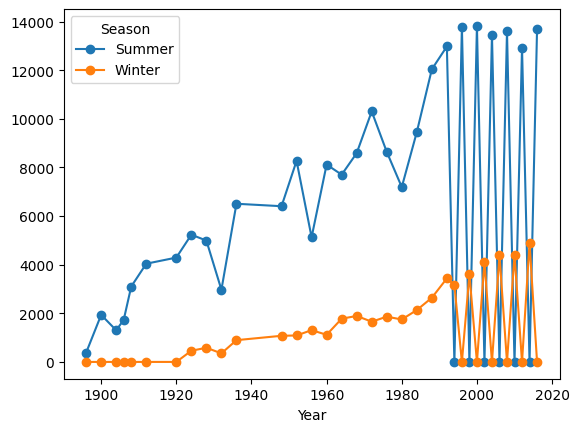

In [ ]:
# Gráfico 4: Temporada y Año.
grafico4 = fusionado.groupby(["Year", "Season"]).size().unstack(fill_value=0)
grafico4.plot(marker="o")

<Axes: xlabel='Year'>

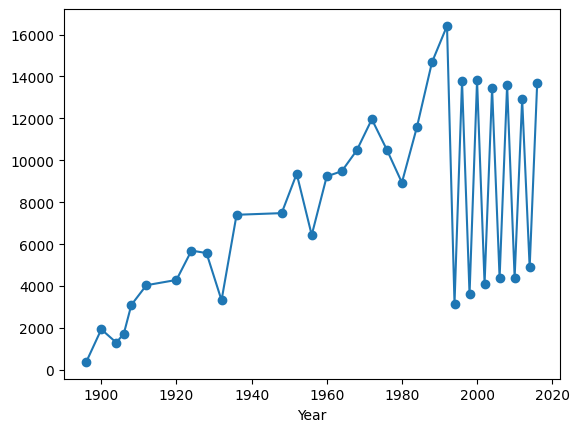

In [ ]:
# Gráfico 5: Temporadas y medallas.
grafico5 = fusionado.groupby("Year")
grafico5["medalla"].size().plot(marker="o")

#14)
Teniendo en cuenta el análisis realizado en el punto 10, la persona que cumple los criterios con mayor porcentaje de probabilidades de ganar una medalla es: Una mujer, que tenga entre 18 y 35 años, de Estados Unidos, y que participe en los juegos de verano.